In [12]:
# ============================================================
# GreenInfer Colab Notebook
# CO₂ and Water Footprint of AI Inference - China Province Analysis
#
# DATA SETUP  choose one option:
#
# Option A: Running from GitHub (anyone can use this)
#   Uncomment the two lines below to clone the repo and get the data files.
#   !git clone https://github.com/GanyaGit/GreenInfer.git
#   import os; os.chdir("GreenInfer")
#
# Option B: Running from Google Drive (original author)
#   Run the cell below to mount your Drive  data loads automatically.
# ============================================================

# Mount Google Drive (skip this if using Option A above)
try:
    from google.colab import drive
    drive.mount('/drive')
    print("Google Drive mounted.")
except Exception:
    print("Not in Colab or Drive already available  skipping mount.")

Drive already mounted at /drive; to attempt to forcibly remount, call drive.mount("/drive", force_remount=True).
Google Drive mounted.


In [13]:
# CELL 2  Install dependencies
!pip install pandas plotly

In [14]:
# CELL 3 -  Province-Level CO₂ Intensity Calculator
# Source: NBS China monthly generation by province
# Coverage: 2024 and 2025 (10 months each, Jan+Feb not released)
# ============================================================

import os
import pandas as pd

CO2_FACTOR_THERMAL = 820  # IPCC AR5 (2014) coal lifecycle gCO₂/kWh
ENERGY_PER_QUERY_KWH = 0.001  # Jegham et al. (2025), arXiv:2505.09598

PUE = 1.27          # Jegham et al. (2025), arXiv:2505.09598, Chinese data centers
WUE_ONSITE = 1.20   # L/kWh on-site, Jegham et al. (2025)
WUE_OFFSITE = 6.016 # L/kWh off-site, Jegham et al. (2025)
# Water: Li et al. (2025), method; Jegham et al. (2025), values


def water_per_query_ml(e_kwh):
    onsite = (e_kwh / PUE) * WUE_ONSITE
    offsite = e_kwh * WUE_OFFSITE
    return (onsite + offsite) * 1000

# - Data directory: GitHub clone takes priority, falls back to Google Drive -
if os.path.exists("data/Monthly By Province-Thermal.csv"):
    DATA_DIR = "data/"
    print("📂 Loading data from: GitHub repo (data/ folder)")
elif os.path.exists("/drive/MyDrive/GreenInfer/data/Monthly By Province-Thermal.csv"):
    DATA_DIR = "/drive/MyDrive/GreenInfer/data/"
    print("📂 Loading data from: Google Drive")
else:
    raise FileNotFoundError(
        "Data files not found.\n"
        "Option A (GitHub): uncomment the git clone lines in Cell 1 and re-run.\n"
        "Option B (Drive):  mount Google Drive in Cell 1 and re-run."
    )

file_names = {
    "thermal": "Monthly By Province-Thermal.csv",
    "hydro":   "Monthly By Province-Hydro.csv",
    "nuclear": "Monthly By Province-Nuclear.csv",
    "wind":    "Monthly By Province-Wind.csv",
    "solar":   "Monthly By Province-Solar.csv",
}

SCALE = 12 / 10  # scale 10 available months → full year

def load_nbs_csv(source, fname):
    df = pd.read_csv(fname, skiprows=2)
    df = df.rename(columns={df.columns[0]: "Region"})
    df = df.set_index("Region")
    df.index = df.index.str.strip()
    return df

print("Loading NBS province data...")
dfs = {}
for source, name in file_names.items():
    path = os.path.join(DATA_DIR, name)
    dfs[source] = load_nbs_csv(source, path)

all_cols = dfs["thermal"].columns.tolist()

def year_cols(year):
    return [c for c in all_cols if str(year) in str(c)]

results = {}
for year in [2024, 2025]:
    cols = year_cols(year)
    result = pd.DataFrame(index=dfs["thermal"].index)

    for src in ["thermal", "hydro", "nuclear", "wind", "solar"]:
        vals = dfs[src][cols].apply(pd.to_numeric, errors="coerce").fillna(0)
        result[f"{src}_sum"] = vals.sum(axis=1) * SCALE

    result["total"] = result[
        ["thermal_sum", "hydro_sum", "nuclear_sum", "wind_sum", "solar_sum"]
    ].sum(axis=1)
    result = result[result["total"] > 0].copy()

    result["co2_intensity"] = (result["thermal_sum"] / result["total"] * CO2_FACTOR_THERMAL).round().astype(int)
    result["co2_per_query_g"] = (ENERGY_PER_QUERY_KWH * result["co2_intensity"]).round(4)
    result["water_per_query_ml"] = round(water_per_query_ml(ENERGY_PER_QUERY_KWH), 4)

    results[year] = result
    print(f"\n{year}  {len(result)} provinces")
    print(result[["co2_intensity"]].sort_values("co2_intensity").to_string())

for year, df in results.items():
    df.to_csv(f"province_co2_{year}.csv")
    print(f"\nSaved: province_co2_{year}.csv")

print("\nSource: NBS China, Monthly Electricity Generation by Province")
print("CO₂ factor: IPCC AR5 (2014)  820 gCO₂/kWh (coal lifecycle)")
print("Water: Li et al. (2025), method; Jegham et al. (2025), arXiv:2505.09598, values")

📂 Loading data from: Google Drive
Loading NBS province data...

2024  31 provinces
                co2_intensity
Region                       
Xizang                     23
Qinghai                    99
Yunnan                    107
Sichuan                   147
Guangxi                   393
Hubei                     411
Gansu                     412
Liaoning                  463
Hunan                     471
Fujian                    478
Jilin                     488
Guizhou                   538
Hainan                    556
Guangdong                 583
Heilongjiang              585
Xinjiang                  595
Zhejiang                  606
Hebei                     611
Ningxia                   618
Inner Mongolia            624
Chongqing                 646
Jiangxi                   665
Jiangsu                   666
Henan                     676
Shandong                  686
Shanxi                    687
Shaanxi                   713
Anhui                     738
Tianjin          

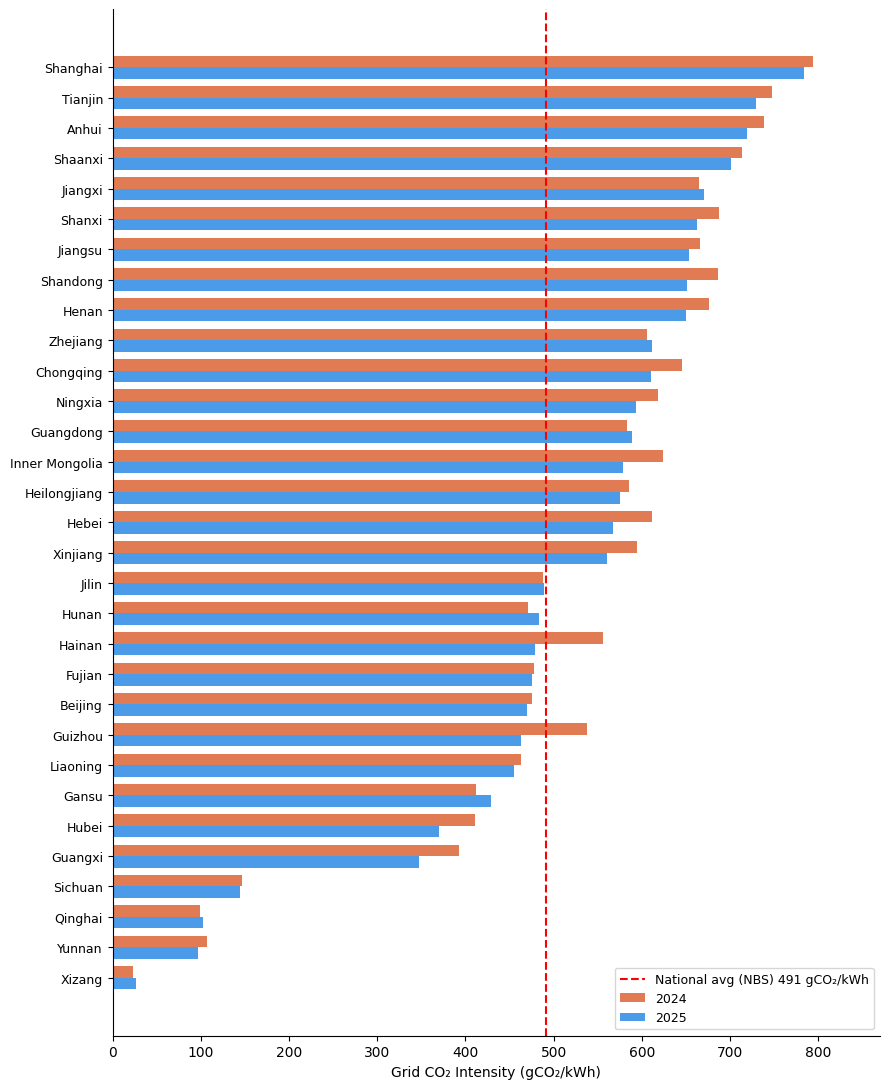

Saved: fig1_provinces.png


In [15]:
# ============================================================
# GreenInfer - Cell 4
# Province CO₂ Intensity - Bar Chart (Figure 1, paper version)
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# Load province results from Cell 3
df2024 = pd.read_csv("province_co2_2024.csv")
df2025 = pd.read_csv("province_co2_2025.csv")

# Override Beijing with gas factor (490 gCO2/kWh, coal-free since 2017)
# Thermal fraction stays the same; only the factor changes: 795*(490/820)≈475, 787*(490/820)≈470
for df, bj_val in [(df2024, 475), (df2025, 470)]:
    df.loc[df["Region"] == "Beijing", "co2_intensity"] = bj_val

# Merge 2024 and 2025
df = df2025[["Region", "co2_intensity"]].rename(columns={"co2_intensity": "2025"})
df = df.merge(df2024[["Region", "co2_intensity"]].rename(columns={"co2_intensity": "2024"}), on="Region")

# Remove national aggregate rows
df = df[~df["Region"].isin(["National Total", "Total"])]

# Sort by 2025 intensity descending (dirtiest on top → cleanest at bottom for horizontal bar)
df = df.sort_values("2025", ascending=True)  # ascending=True so dirtiest is at the top of the chart

# NBS national average (same method as provinces)
NBS_NATIONAL_2025 = 491  # from AnnualNational file, coal factor

# ---- Plot ----
fig, ax = plt.subplots(figsize=(9, 11))

y = np.arange(len(df))
bar_h = 0.38

bars2024 = ax.barh(y + bar_h/2, df["2024"], height=bar_h, color="#E07B54", label="2024")
bars2025 = ax.barh(y - bar_h/2, df["2025"], height=bar_h, color="#4C9BE8", label="2025")

# Red reference line — NBS national average
ax.axvline(x=NBS_NATIONAL_2025, color="red", linestyle="--", linewidth=1.5,
           label=f"National avg (NBS) {NBS_NATIONAL_2025} gCO₂/kWh")

ax.set_yticks(y)
ax.set_yticklabels(df["Region"], fontsize=9)
ax.set_xlabel("Grid CO₂ Intensity (gCO₂/kWh)", fontsize=10)
ax.set_xlim(0, 870)
ax.legend(fontsize=9, loc="lower right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
# NO plt.title() — caption is added by LaTeX

plt.tight_layout()
plt.savefig("fig1_provinces.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved: fig1_provinces.png")

Unique electricity sources in dataset for China: ['Solar', 'Wind', 'Hydro', 'Bioenergy', 'Nuclear', 'Coal', 'Gas', 'Other fossil', 'Wind and solar', 'Hydro, bioenergy and other renewables', 'Renewables', 'Clean', 'Fossil', 'Total generation', 'Demand', 'Net imports']

China CO2 intensity from Ember (gCO2/kWh):
 Year   Value
 2000 783.511
 2001 762.877
 2002 773.301
 2003 790.918
 2004 778.518
 2005 782.122
 2006 786.685
 2007 785.282
 2008 747.115
 2009 753.204
 2010 742.450
 2011 754.005
 2012 721.700
 2013 719.127
 2014 695.753
 2015 669.705
 2016 653.311
 2017 646.279
 2018 639.097
 2019 621.993
 2020 609.048
 2021 602.329
 2022 589.968
 2023 586.366
 2024 558.965
 2025 528.278


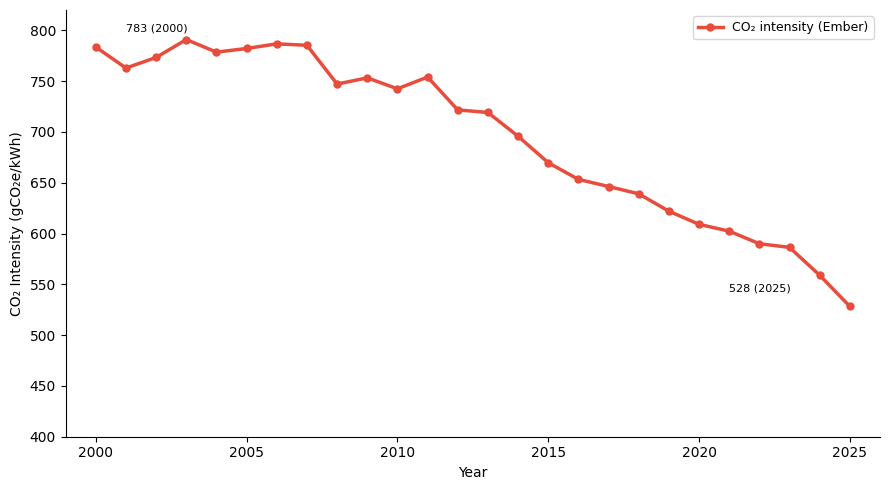

Saved: fig2_china_trend.png


In [16]:
# ============================================================
# GreenInfer - Cell 5
# National Annual CO₂ Intensity Trend 2000–2025 (Figure 2, paper version)
# Source: Ember Yearly Electricity Data only
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

# Load Ember global CSV
if os.path.exists("data/release_generation_yearly_global.csv"):
    ember_path = "data/release_generation_yearly_global.csv"
elif os.path.exists("/drive/MyDrive/GreenInfer/data/release_generation_yearly_global.csv"):
    ember_path = "/drive/MyDrive/GreenInfer/data/release_generation_yearly_global.csv"
else:
    raise FileNotFoundError("release_generation_yearly_global.csv not found.")

ember = pd.read_csv(ember_path)

# Filter for China first
china_all = ember[ember["Area"] == "China"]

# Let's see how 'Total' is written in the Electricity source column
unique_sources = china_all["Electricity source"].unique() if "Electricity source" in china_all.columns else []
print("Unique electricity sources in dataset for China:", list(unique_sources))

# Fallback matching: try "Total" or "Total generation" or another logical default
target_source = "Total"
for src in ["Total", "Total generation", "Total Grid", "All Sources"]:
    if src in unique_sources:
        target_source = src
        break

# Filter for target source
china = china_all[china_all["Electricity source"] == target_source].copy()

# Extract the intensity metric directly
intensity_col = "Emissions intensity (gCO2e/kWh)"
china = china[["Year", intensity_col]].dropna()
china.columns = ["Year", "Value"]
china = china.sort_values("Year")
china = china[china["Year"].between(2000, 2025)]

if china.empty:
    print("\n⚠️ Warning: China dataframe is still empty. Displaying available data for China in 2024/2025:")
    print(china_all[china_all["Year"].between(2024, 2025)][["Year", "Electricity source", intensity_col]].dropna().head(10))
    raise ValueError("No matching grid emission intensity rows found for China total grid in the CSV file.")

print("\nChina CO2 intensity from Ember (gCO2/kWh):")
print(china.to_string(index=False))

# ---- Plot ----
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(china["Year"], china["Value"],
        color="#E74C3C", linewidth=2.5, marker="o", markersize=5,
        label="CO₂ intensity (Ember)")

# Annotate start and end
start = china.iloc[0]
end = china.iloc[-1]
ax.annotate(f'{int(start["Value"])} (2000)',
            xy=(start["Year"], start["Value"]),
            xytext=(2001, start["Value"] + 15), fontsize=8)
ax.annotate(f'{int(end["Value"])} ({int(end["Year"])})',
            xy=(end["Year"], end["Value"]),
            xytext=(end["Year"] - 4, end["Value"] + 15), fontsize=8)

ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("CO₂ Intensity (gCO₂e/kWh)", fontsize=10)
ax.set_xlim(1999, 2026)
ax.set_ylim(400, 820)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig("fig2_china_trend.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved: fig2_china_trend.png")